# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis,
**Crest** neural crest) were scored in 02 against the shared **union** control pool and
graph-smoothed. Here we render them as deliverables and evaluate **Gate 2**.

**Gate 2 (non-branching case).** Puram's branching manifold splits Gast and pSom into
*distinct arms* with Crest terminal. A non-branching manifold instead shows a **single
developmental gradient** along the trajectory body with an inverse terminal end. In Lin 2020
that gradient is the **posterior-somitogenesis → neural-crest** axis: pSom is high over the
ductal body and falls along pseudotime (rho ≈ −0.59) while Crest rises to a terminal end
(rho ≈ +0.32; Crest-high decile at pseudotime ≈ 0.82), the two being anti-correlated in
space (r ≈ −0.38). Gastrulation is only weakly structured (rho ≈ −0.24; an *early* embryonic
programme, largely spent in this late epithelial lineage). Crest is terminal — **not** on the
Gast end — so **no inversion flag**. The single-axis, inverse-terminal pattern **is present**,
so **Gate 2 = GO**; with no bifurcation the cross-repression test is **Gate 3 = NA**.

**Proliferation caveat (carried from 02).** The Crest terminus coincides with the Cycling
lobe (pseudotime vs cycling rho ≈ +0.42). This is a caveat, not a confound: the module gene
sets are cell-cycle-free and the pSom→Crest axis holds within the non-cycling lobe alone
(02), so the axis *identity* is developmental (Zhou 2020 precedent), while its terminal end
is proliferation-enriched.

**Contrast with Peng 2019 (same tissue, NO-GO).** The raw module means here (Gast −0.008 /
pSom +0.046 / Crest −0.006) resemble the failed Peng 2019 PDAC run (−0.047 / +0.097 /
−0.055) — pSom-dominant. What separates GO from NO-GO is **not** the scalar means but the
*geography*: Peng showed mutually-exclusive module territories with no terminal Crest
readout, whereas Lin resolves into a single pSom→Crest axis with Crest genuinely terminal.
Deliverable: `signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 10304 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 78/81 genes present
pSom: 89/98 genes present
Crest: 101/104 genes present


### Gate 2 — module geography on the manifold
Quantitative test of the non-branching signature: (i) the dominant developmental contrast is
pSom vs Crest (spatial anti-correlation); (ii) along pseudotime pSom declines and Crest rises
(Crest terminal); (iii) Gast is weakly structured and not co-linear (early programme, spent).
We also report the joint pSom&Crest-high enrichment: a co-expression hub (Puram signature)
would show enrichment > 1, whereas a clean inverse gradient shows depletion (< 1).

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
pz = (adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
cz = (adata.obs['Crest']-adata.obs['Crest'].mean())/adata.obs['Crest'].std()
joint = ((pz>0.5)&(cz>0.5)).mean(); exp = (pz>0.5).mean()*(cz>0.5).mean()
print(f'joint pSom&Crest-high enrichment = {joint/exp:.2f} (<1 = inverse gradient, not a hub)')
crest_gast = np.corrcoef(adata.obs['Crest_sm'], adata.obs['Gast_sm'])[0,1]
print(f'Crest vs Gast spatial r = {crest_gast:+.2f} (Crest terminal, not on the Gast end -> no inversion flag)')
print('Gate 2: single pSom->Crest gradient + inverse terminal Crest -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.21
  Crest_sm vs Gast_sm: r = -0.04
  Crest_sm vs pSom_sm: r = -0.38
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.238
  pSom_sm: rho = -0.593
  Crest_sm: rho = +0.315
Neural-crest-high decile mean pseudotime = 0.82 (terminal if ~1)
joint pSom&Crest-high enrichment = 0.52 (<1 = inverse gradient, not a hub)
Crest vs Gast spatial r = -0.04 (Crest terminal, not on the Gast end -> no inversion flag)
Gate 2: single pSom->Crest gradient + inverse terminal Crest -> GO (non-branching)
Gate 3: no bifurcation -> NA


### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right (`X_umap_lin`), `size=30`, plasma,
**raw** (not smoothed) score per cell so 10x dropout is visible (the reference shows raw).
Colorbar ticks data-driven.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


<ipython-input-5-aa803c4edd06>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
<ipython-input-5-aa803c4edd06>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
<ipython-input-5-aa803c4edd06>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)


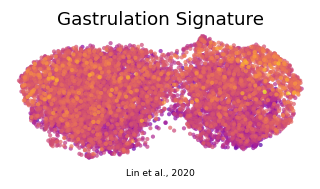

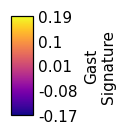

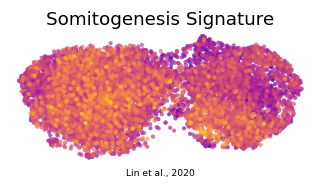

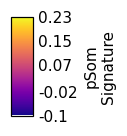

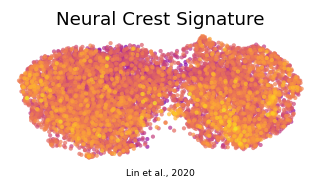

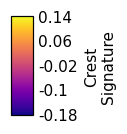

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Lin et al., 2020', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (10304, 21706)
